# D3 — Flight Delay Analysis
**Course:** IT135IU — Introduction to Data Science  
**Group:** 09

| Name | Student ID | Role |
|---|---|---|
| Van Ngo Chi Thien | ITDSIU25042 | Product owner / Team leader |
| Nguyen Tri Tin | ITDSIU25047 | Data engineer – sources |
| Nguyen Minh Khoi | ITDSIU25017 | Data engineer – integration |
| Nguyen Hai Quan | ITDSIU25032 | Data analyst |
| Truong Trung Tin | ITDSIU25048 | Visualisation lead |
| Vo Ngoc Quynh Nhu | ITDSIU24060 | Reproducibility lead |
| Nguyen Pham Nhat Minh | ITDSIU25022 | Ethics and privacy officer |

### 3. Descriptive Statistics for Flight Delays by Route

We analyse routes by airline, origin, and destination. A flight is classified as delayed if it arrives at least 15 minutes late (`arr_delay >= 15`). A route is eligible if at least 100 flights on that route have a recorded `arr_delay` value.

In [7]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"pkg_resources is deprecated as an API.*",
        category=UserWarning,
    )
    from nycflights13 import flights, airlines

df_working = flights.merge(
    airlines[["carrier", "name"]],
    on="carrier",
    how="left",
    validate="many_to_one",
)

print(f"Merged dataset: {len(df_working):,} rows, {df_working.shape[1]} columns")
print(f"Rows with missing airline names: {df_working['name'].isna().sum():,}")

Merged dataset: 336,776 rows, 20 columns
Rows with missing airline names: 0


In [2]:
import pandas as pd
import numpy as np

# 1. Baseline overview & missingness
total_raw_flights = len(df_working)
missing_arr_delay = df_working['arr_delay'].isna().sum()
df_clean_delays = df_working.dropna(subset=['arr_delay']).copy()

# Define delay flag (>= 15 minutes)
df_clean_delays['is_delayed'] = df_clean_delays['arr_delay'] >= 15

print(f"Total raw flights: {total_raw_flights:,}")
print(f"Flights with missing arrival delay: {missing_arr_delay:,} ({missing_arr_delay/total_raw_flights:.2%})")
print(f"Valid flights for delay analysis: {len(df_clean_delays):,}")
baseline_rate = df_clean_delays["is_delayed"].mean()
print(f"Overall arrival delay rate: {baseline_rate:.2%}")

# 2. Aggregating by Route (Carrier - Origin - Dest)
route_stats = df_clean_delays.groupby(['carrier', 'origin', 'dest']).agg(
    total_flights=('arr_delay', 'count'),
    delayed_flights=('is_delayed', 'sum'),
    median_delay=('arr_delay', 'median'),
    mean_delay=('arr_delay', 'mean')
).reset_index()

# 3. Calculate delay rate (%)
route_stats['delay_rate'] = (route_stats['delayed_flights'] / route_stats['total_flights']) * 100

# 4. Filter for routes with >= 100 flights
eligible_routes = route_stats[route_stats['total_flights'] >= 100].copy()
eligible_routes = eligible_routes.sort_values(by='delay_rate', ascending=False).reset_index(drop=True)

print(f"\nTotal unique routes: {len(route_stats)} | Eligible routes (>=100 flights): {len(eligible_routes)}")

# Display Top 10 Chronic Delay Routes
top_10_routes = eligible_routes.head(10)
top_10_routes.style.format({
    'total_flights': '{:,}',
    'delayed_flights': '{:,}',
    'delay_rate': '{:.2f}%',
    'median_delay': '{:.1f} min',
    'mean_delay': '{:.1f} min'
})

Total raw flights: 336,776
Flights with missing arrival delay: 9,430 (2.80%)
Valid flights for delay analysis: 327,346
Overall arrival delay rate: 24.47%

Total unique routes: 437 | Eligible routes (>=100 flights): 314


,carrier,origin,dest,total_flights,delayed_flights,median_delay,mean_delay,delay_rate
0,EV,EWR,OKC,315,163,16.0 min,30.6 min,51.75%
1,EV,EWR,TYS,313,155,14.0 min,41.2 min,49.52%
2,EV,EWR,TUL,294,145,14.0 min,33.7 min,49.32%
3,EV,EWR,RIC,"1,615",658,6.0 min,25.8 min,40.74%
4,WN,EWR,DEN,675,269,7.0 min,19.1 min,39.85%
5,EV,EWR,MEM,845,336,5.0 min,19.9 min,39.76%
6,EV,EWR,DCA,"1,565",616,5.0 min,21.3 min,39.36%
7,9E,JFK,CLE,314,123,4.0 min,22.5 min,39.17%
8,EV,EWR,MSN,345,135,5.0 min,23.2 min,39.13%
9,F9,LGA,DEN,681,264,6.0 min,21.9 min,38.77%


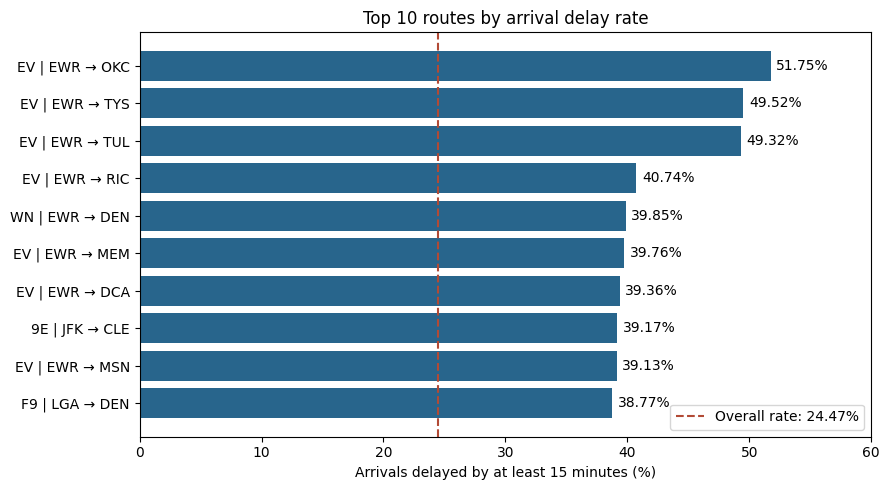

In [3]:
import matplotlib.pyplot as plt

plot_data = top_10_routes.iloc[::-1].copy()
labels = (
    plot_data["carrier"] + " | "
    + plot_data["origin"] + " → " + plot_data["dest"]
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels, plot_data["delay_rate"], color="#28658c")
ax.bar_label(bars, fmt="%.2f%%", padding=4)

ax.axvline(
    baseline_rate * 100,
    color="#b24a35",
    linestyle="--",
    label=f"Overall rate: {baseline_rate:.2%}",
)

ax.set(
    title="Top 10 routes by arrival delay rate",
    xlabel="Arrivals delayed by at least 15 minutes (%)",
    xlim=(0, 60),
)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### Key Observation: Top Chronic Delay Routes
- Baseline delay rate across all flights in 2013 is evaluated to compare against high-risk routes.
- The table above ranks the top eligible routes by their **Arrival Delay Rate (>= 15 mins)**. 
- Using median delay alongside mean delay helps prevent extreme outliers (e.g., severe weather delays of several hours) from distorting the general performance of a route.

In [4]:
# Select top 3 routes for deep-dive monthly analysis
top_3_keys = top_10_routes.head(3)[['carrier', 'origin', 'dest']]

# Filter dataset for top 3 routes
monthly_analysis = df_clean_delays.merge(top_3_keys, on=['carrier', 'origin', 'dest'])

# Aggregate monthly metrics for top 3 routes
monthly_summary = monthly_analysis.groupby(['carrier', 'origin', 'dest', 'month']).agg(
    monthly_flights=('arr_delay', 'count'),
    monthly_delayed=('is_delayed', 'sum'),
    monthly_median_delay=('arr_delay', 'median')
).reset_index()

monthly_summary['monthly_delay_rate'] = (monthly_summary['monthly_delayed'] / monthly_summary['monthly_flights']) * 100

# Pivot table for clean presentation of monthly delay rates (%)
monthly_pivot = monthly_summary.pivot(
    index=['carrier', 'origin', 'dest'],
    columns='month',
    values='monthly_delay_rate'
)
monthly_pivot.columns = [f"M{m}" for m in monthly_pivot.columns]
monthly_pivot.style.format("{:.1f}%")

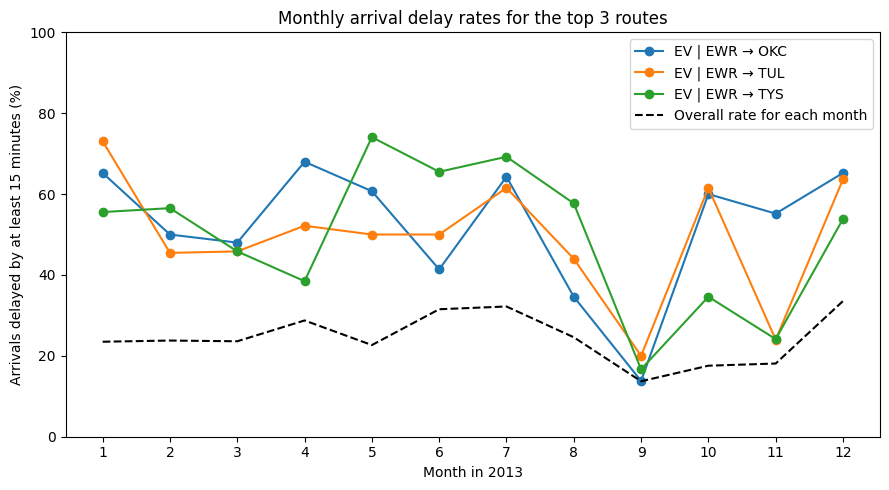

In [5]:
monthly_baseline = df_clean_delays.groupby("month")["is_delayed"].mean() * 100
months = range(1, 13)

fig, ax = plt.subplots(figsize=(9, 5))

for (carrier, origin, dest), group in monthly_summary.groupby(
    ["carrier", "origin", "dest"]
):
    by_month = group.set_index("month").reindex(months)
    rates = by_month["monthly_delay_rate"].where(by_month["monthly_flights"] >= 10)
    ax.plot(months, rates, marker="o", label=f"{carrier} | {origin} → {dest}")

ax.plot(
    months, monthly_baseline.reindex(months),
    color="black", linestyle="--", label="Overall rate for each month",
)
ax.set(
    title="Monthly arrival delay rates for the top 3 routes",
    xlabel="Month in 2013",
    ylabel="Arrivals delayed by at least 15 minutes (%)",
    xticks=list(months),
    ylim=(0, 100),
)
ax.legend()
fig.tight_layout()
plt.show()

#### Monthly Consistency Analysis

All three routes exceeded the overall delay rate for the corresponding month in all 12 months of 2013. The gap for EWR → OKC in September was only 0.08 percentage points. This pattern supports reviewing the three routes. The monthly comparison cannot identify what caused the delays.

Routes analysed: 314
Spearman correlation: -0.151


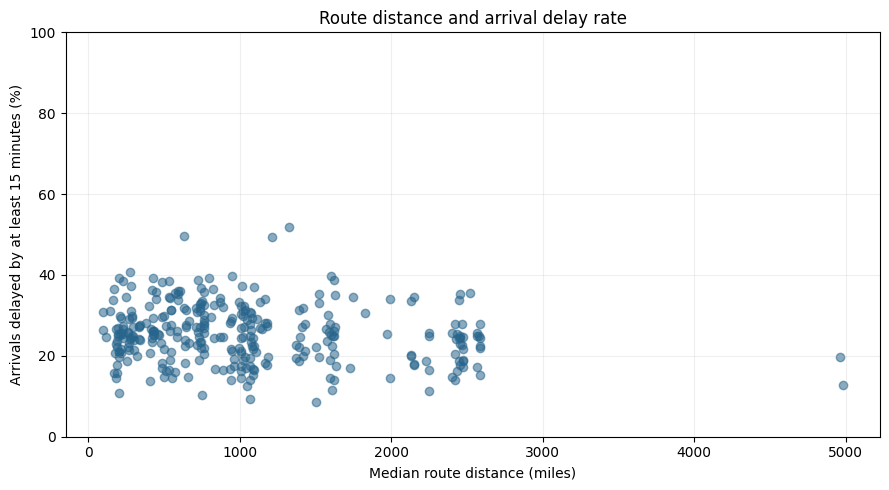

In [6]:
route_cols = ["carrier", "origin", "dest"]

route_distance = (
    df_working.groupby(route_cols)["distance"]
    .median()
    .rename("distance_miles")
    .reset_index()
)

distance_analysis = eligible_routes.merge(
    route_distance, on=route_cols, validate="one_to_one"
).dropna(subset=["distance_miles", "delay_rate"])

# Spearman correlation is the Pearson correlation of the ranks.
rho = distance_analysis["distance_miles"].rank().corr(
    distance_analysis["delay_rate"].rank()
)

print(f"Routes analysed: {len(distance_analysis):,}")
print(f"Spearman correlation: {rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    distance_analysis["distance_miles"],
    distance_analysis["delay_rate"],
    alpha=0.55,
    color="#28658c",
)
ax.set(
    title="Route distance and arrival delay rate",
    xlabel="Median route distance (miles)",
    ylabel="Arrivals delayed by at least 15 minutes (%)",
    ylim=(0, 100),
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Interpretation: Route distance and arrival delays

Across 314 eligible routes, median route distance and arrival delay rate had a weak negative Spearman correlation (ρ = −0.151). Longer routes tended to have slightly lower delay rates, but the rates varied widely among routes of similar distance. Distance alone is not a reliable guide for choosing which routes to review.

This analysis does not establish causation. It does not control for airline, airport congestion, weather, or scheduling, and the delay rates include only flights with a recorded arrival delay.

## Conclusion and Recommendation

The airline's operations team should review these three EV routes from Newark (EWR) first:

| Priority | Route | Delayed / observed arrivals | Delay rate |
|---|---|---:|---:|
| 1 | EWR → OKC | 163 / 315 | 51.75% |
| 2 | EWR → TYS | 155 / 313 | 49.52% |
| 3 | EWR → TUL | 145 / 294 | 49.32% |

All three routes had roughly twice the overall delay rate of 24.47% and exceeded the corresponding monthly baseline in all 12 months of 2013.

The team should check scheduling, aircraft turnaround times, and disruption logs, then verify whether the pattern persists in recent data before changing schedules. The analysis describes flights departing NYC in 2013. It excludes flights without a recorded arrival delay and does not identify what caused the delays.